# Day 13 — Exploratory Data Analysis (EDA) and Business Questions

**Project:** Sales Performance Analysis  
**Objective:** Explore 100 sample sales records, answer five business questions, and document findings and limitations.

> This is synthetic practice data, not real company data. Run each code cell in order and write your own interpretation below the outputs.

## 1. Import libraries

Pandas is used to inspect and analyze tabular data. Matplotlib is used to create charts.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("Day13_Sales_100_Records.csv")
df.head()

,OrderID,OrderDate,Product,Category,Region,SalesChannel,CustomerSegment,Quantity,UnitPrice,DiscountPct,Sales
0,ORD001,2026-09-24,Headphones,Accessories,Mumbai,Online,Corporate,3,2700,0.00,8100.0
1,ORD002,2026-10-17,Keyboard,Accessories,Mumbai,Phone,Small Business,2,1100,0.15,1870.0
2,ORD003,2026-07-02,Laptop,Electronics,Nashik,Online,Individual,1,53000,0.15,45050.0
3,ORD004,2026-10-10,Headphones,Accessories,Nashik,Retail Store,Individual,7,3700,0.00,25900.0
4,ORD005,2026-09-24,Printer,Electronics,Nashik,Retail Store,Corporate,3,13500,0.10,36450.0


## 2. Understand the dataset

Check the number of rows and columns, column names, data types, and basic statistics.

In [2]:
print("Rows and columns:", df.shape)
print("\\nColumn names:", df.columns.tolist())
df.info()
df.describe(include="all")

Rows and columns: (100, 11)
\nColumn names: ['OrderID', 'OrderDate', 'Product', 'Category', 'Region', 'SalesChannel', 'CustomerSegment', 'Quantity', 'UnitPrice', 'DiscountPct', 'Sales']
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          100 non-null    str    
 1   OrderDate        100 non-null    str    
 2   Product          100 non-null    str    
 3   Category         100 non-null    str    
 4   Region           100 non-null    str    
 5   SalesChannel     100 non-null    str    
 6   CustomerSegment  100 non-null    str    
 7   Quantity         100 non-null    int64  
 8   UnitPrice        100 non-null    int64  
 9   DiscountPct      100 non-null    float64
 10  Sales            100 non-null    float64
dtypes: float64(2), int64(2), str(7)
memory usage: 14.8 KB


,OrderID,OrderDate,Product,Category,Region,SalesChannel,CustomerSegment,Quantity,UnitPrice,DiscountPct,Sales
count,100,100,100,100,100,100,100,100.000000,100.000000,100.000000,100.00000
unique,100,71,8,2,5,3,3,NaN,NaN,NaN,NaN
top,ORD001,2026-07-21,Laptop,Accessories,Mumbai,Online,Corporate,NaN,NaN,NaN,NaN
freq,1,3,18,58,22,37,36,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.590000,13721.000000,0.063000,29548.25000
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.340228,19540.547303,0.058439,41105.48083
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,300.000000,0.000000,500.00000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1100.000000,0.000000,3400.00000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2700.000000,0.050000,12835.00000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.000000,15250.000000,0.100000,32415.00000


## 3. Data quality checks

Check missing values, exact duplicate rows, and duplicate order IDs. Convert OrderDate to a date type.

In [3]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"], errors="coerce")

print("Missing values by column:")
print(df.isna().sum())

print("\\nExact duplicate rows:", df.duplicated().sum())
print("Duplicate OrderIDs:", df["OrderID"].duplicated().sum())

print("\\nInvalid or non-positive quantity rows:")
display(df[df["Quantity"] <= 0])

print("\\nDate range:", df["OrderDate"].min(), "to", df["OrderDate"].max())

Missing values by column:
OrderID            0
OrderDate          0
Product            0
Category           0
Region             0
SalesChannel       0
CustomerSegment    0
Quantity           0
UnitPrice          0
DiscountPct        0
Sales              0
dtype: int64
\nExact duplicate rows: 0
Duplicate OrderIDs: 0
\nInvalid or non-positive quantity rows:


,OrderID,OrderDate,Product,Category,Region,SalesChannel,CustomerSegment,Quantity,UnitPrice,DiscountPct,Sales


\nDate range: 2026-07-01 00:00:00 to 2026-10-28 00:00:00


## 4. Define five business questions

1. Which product generates the most revenue?
2. Which region generates the most revenue?
3. What percentage of total revenue comes from each product?
4. What is the average order value (AOV)?
5. How do sales change over time?

**Metrics:** Total sales, product-wise sales, region-wise sales, revenue contribution %, average order value, and monthly sales.

## 5. Overall KPIs

In [4]:
total_sales = df["Sales"].sum()
total_orders = df["OrderID"].nunique()
total_quantity = df["Quantity"].sum()
aov = total_sales / total_orders if total_orders else 0

print(f"Total Sales: ₹{total_sales:,.2f}")
print(f"Unique Orders: {total_orders}")
print(f"Total Quantity: {total_quantity}")
print(f"Average Order Value: ₹{aov:,.2f}")

Total Sales: ₹2,954,825.00
Unique Orders: 100
Total Quantity: 359
Average Order Value: ₹29,548.25


## 6. Business Question 1 — Which product generates the most revenue?

,Product,Sales
2,Laptop,1931235.0
5,Printer,341560.0
3,Monitor,257315.0
0,Headphones,159235.0
7,Webcam,130970.0
1,Keyboard,70010.0
6,USB Drive,46645.0
4,Mouse,17855.0


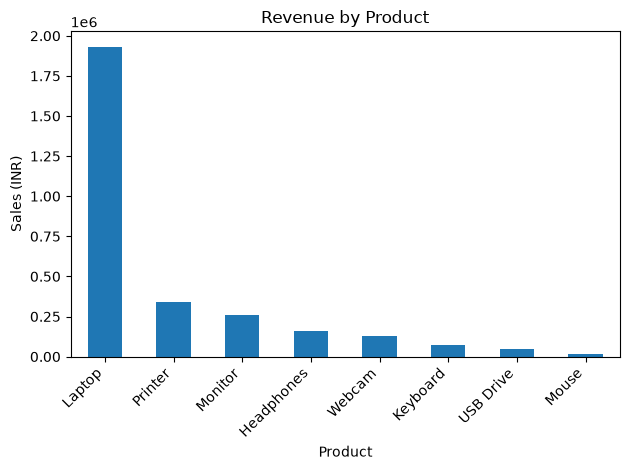

In [5]:
product_sales = (
    df.groupby("Product", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)
display(product_sales)

product_sales.plot(kind="bar", x="Product", y="Sales", legend=False, title="Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Finding:** After running the cell, write which product has the highest total sales and its value.

## 7. Business Question 2 — Which region generates the most revenue?

,Region,Sales
1,Mumbai,871260.0
3,Nashik,579635.0
4,Pune,567650.0
2,Nagpur,488670.0
0,Chhatrapati Sambhajinagar,447610.0


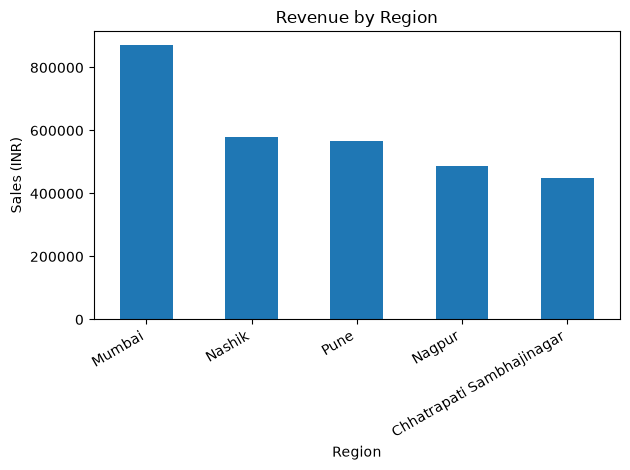

In [6]:
region_sales = (
    df.groupby("Region", as_index=False)["Sales"]
      .sum()
      .sort_values("Sales", ascending=False)
)
display(region_sales)

region_sales.plot(kind="bar", x="Region", y="Sales", legend=False, title="Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Finding:** Write the highest-revenue region and compare it with the other regions.

## 8. Business Question 3 — What is each product's revenue contribution?

In [7]:
product_contribution = (
    df.groupby("Product")["Sales"].sum()
      .div(df["Sales"].sum())
      .mul(100)
      .sort_values(ascending=False)
      .round(2)
)
display(product_contribution.rename("Revenue Contribution (%)").to_frame())

,Revenue Contribution (%)
Product,
Laptop,65.36
Printer,11.56
Monitor,8.71
Headphones,5.39
Webcam,4.43
Keyboard,2.37
USB Drive,1.58
Mouse,0.60


**Finding:** Identify the product with the largest revenue share. A high revenue share does not automatically mean highest profit because costs are not included.

## 9. Business Question 4 — What is the average order value?

In [8]:
aov = df["Sales"].sum() / df["OrderID"].nunique()
print(f"Average Order Value (AOV): ₹{aov:,.2f}")

Average Order Value (AOV): ₹29,548.25


**Interpretation:** AOV is total sales divided by unique orders. Here each OrderID represents one order.

## 10. Business Question 5 — How do sales change over time?

,Sales
OrderDate,
2026-07-01,1192065.0
2026-08-01,627180.0
2026-09-01,805055.0
2026-10-01,330525.0


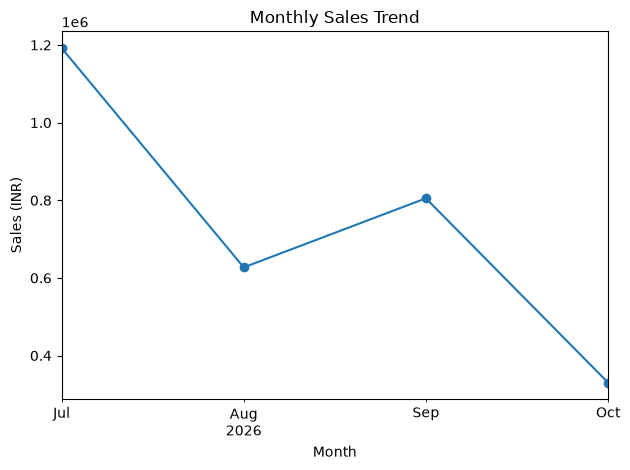

In [9]:
monthly_sales = (
    df.set_index("OrderDate")
      .resample("MS")["Sales"]
      .sum()
)
display(monthly_sales.rename("Sales").to_frame())

monthly_sales.plot(kind="line", marker="o", title="Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.tight_layout()
plt.show()

**Finding:** Describe which month has the highest sales. Do not claim long-term seasonality from only four months of sample data.

## 11. Business Questions, Metrics and Findings Mapping Table

Fill in the Findings column after running the cells above.

In [10]:
mapping = pd.DataFrame({
    "Business Question": [
        "Which product generates the most revenue?",
        "Which region generates the most revenue?",
        "What is each product's revenue contribution?",
        "What is the average order value?",
        "How do sales change over time?"
    ],
    "Metric": [
        "Product-wise total Sales",
        "Region-wise total Sales",
        "Product Sales / Total Sales × 100",
        "Total Sales / Unique OrderID count",
        "Monthly total Sales"
    ],
    "Finding": [
        "Write finding from product_sales output",
        "Write finding from region_sales output",
        "Write finding from product_contribution output",
        f"AOV = ₹{aov:,.2f}",
        "Write finding from monthly_sales output"
    ]
})
display(mapping)

,Business Question,Metric,Finding
0,Which product generates the most revenue?,Product-wise total Sales,Write finding from product_sales output
1,Which region generates the most revenue?,Region-wise total Sales,Write finding from region_sales output
2,What is each product's revenue contribution?,Product Sales / Total Sales × 100,Write finding from product_contribution output
3,What is the average order value?,Total Sales / Unique OrderID count,"AOV = ₹29,548.25"
4,How do sales change over time?,Monthly total Sales,Write finding from monthly_sales output


## 12. Limitations

- This is synthetic practice data, not real company data.
- The dataset covers only July–October 2026, so long-term trends cannot be established.
- There is no cost, returns, or profit data; therefore, profitability cannot be measured.
- Each OrderID is treated as one order.
- Observed patterns are descriptive and do not prove cause and effect.

## 13. Conclusion

Write 3–5 sentences summarizing the strongest findings, a cautious business recommendation, and the key data limitations.